# **Part A — Build a problem worth studying**
## **TASK 01 — Make a model that overfits**

**Objectives :-**  
- Build a neural network that clearly overfits a small training dataset.
- We will use the handwritten digits dataset.
- The model will be trained on only 300 examples so that it can memorize the training data.
- We will compare training loss, validation loss and validation accuracy to understand overfitting.

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import copy
import time

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Load Dataset
digits = load_digits()

X = StandardScaler().fit_transform(digits.data)
y = digits.target

# Split dataset
X_train, X_remaining, y_train, y_remaining = train_test_split(X, y, train_size=300, random_state=0, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_remaining, y_remaining, test_size=0.5, random_state=0, stratify=y_remaining)

def to_tensor(data, labels=False):
    if labels:
        return torch.tensor(data, dtype=torch.long).to(device)
    return torch.tensor(data, dtype=torch.float32).to(device)


Xtr = to_tensor(X_train)
ytr = to_tensor(y_train, True)

Xva = to_tensor(X_val)
yva = to_tensor(y_val, True)

Xte = to_tensor(X_test)
yte = to_tensor(y_test, True)


print("Training Samples:", len(Xtr))
print("Validation Samples:", len(Xva))
print("Testing Samples:", len(Xte))
print("Device:", device)

Training Samples: 300
Validation Samples: 748
Testing Samples: 749
Device: cuda


**Dataset Information :-**  
The Digits dataset contains handwritten numbers from 0 to 9.  
Each image contains 8 × 8 pixels.  
Therefore, every image has 64 input features.  
Our dataset is divided into:
- Training: 300 samples
- Validation: Approximately 748 samples
- Testing: Approximately 749 samples

Training data is used for learning.  
Validation data is used for model selection.  
Test data is reserved for final evaluation.

In [3]:
# Build neural network
def make_model(hidden=265, depth=2, dropout=0.0, batchnorm=False, seed=0):
    torch.manual_seed(seed)

    layers = []
    n_in = 64

    for _ in range(depth):
        layers.append(nn.Linear(n_in, hidden))

        if batchnorm:
            layers.append(nn.BatchNorm1d(hidden))

        layers.append(nn.ReLU())

        if dropout > 0:
            layers.append(nn.Dropout(dropout))

        n_in = hidden

    layers.append(nn.Linear(hidden, 10))

    return nn.Sequential(* layers).to(device)


print(make_model())

Sequential(
  (0): Linear(in_features=64, out_features=265, bias=True)
  (1): ReLU()
  (2): Linear(in_features=265, out_features=265, bias=True)
  (3): ReLU()
  (4): Linear(in_features=265, out_features=10, bias=True)
)


In [4]:
# Create the Train Function
def train(model, epochs=150, lr=0.001, weight_decay=0.0, scheduler=None,
         patience=None, batch_size=64, verbose=False, stop_metric="loss",
         restore_best=True, optimizer_name="adam", label_smoothing=0.0):
    torch.manual_seed(0)

    if optimizer_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError("Unknown optimizer")


    sched = scheduler(optimizer) if scheduler else None
    loss_fn = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": [],
        "lr": []
    }


    best_score = float("inf") if stop_metric == "loss" else -float("inf")

    best_state = None
    bad_epochs = 0
    stopped_at = epochs
    best_epoch = 0

    for epoch in range(epochs):
        model.train()
        permutation = torch.randperm(len(Xtr), device=device)
        total_loss = 0

        for i in range(0, len(Xtr), batch_size):
            indices = permutation[i:i + batch_size]
            optimizer.zero_grad()
            predictions = model(Xtr[indices])
            loss = loss_fn(predictions, ytr[indices])
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(indices)

        model.eval()

        with torch.no_grad():
            val_predictions = model(Xva)
            val_loss = loss_fn(val_predictions, yva).item()
            val_acc = (val_predictions.argmax(1) == yva).float().mean().item()
        
        train_loss = total_loss / len(Xtr)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if sched is not None:
            if isinstance(sched, torch.optim.lr_scheduler.ReduceLROnPlateau):
                sched.step(val_loss)
            else:
                sched.step()

        current_score = (val_loss if stop_metric == "loss" else val_acc)
        improved = (current_score < best_score - 1e-4
                   if stop_metric == "loss"
                   else current_score > best_score + 1e-4)
        if improved :
            best_score = current_score
            best_epoch = epoch + 1
            bad_epoch = 0
            best_state = copy.deepcopy(model.state_dict())

        else:
            bad_epochs += 1

            if patience is not None and bad_epochs >= patience:
                stopped_at = epoch + 1

                if restore_best and best_state is None:
                    model.load_state_dict(best_state)

                break


    if restore_best and patience is None and best_state is not None:
        model.load_state_dict(best_state)

    history["stopped_at"] = stopped_at
    history["best_epoch"] = best_epoch

    model.eval()

    with torch.no_grad():

        final_predictions = model(Xva)
        history["final_val_acc"] = (final_predictions.argmax(1) == yva).float().mean().item()

    history["final_val_loss"] = nn.CrossEntropyLoss()(model(Xva), yva).item()
    return history, model


print("Training function ready!")

Training function ready!


In [5]:
# Train baseline model
start_time = time.time()

baseline_history, baseline_model = train(make_model(), epochs=150, lr=0.001)

training_time = time.time() - start_time

print("Training Time", round(training_time, 2), "seconds")
print("Minimum Validation Loss:", round(min(baseline_history["val_loss"]), 4))
print("Final Validation Accuracy:", round(baseline_history["final_val_acc"], 4))

Training Time 5.1 seconds
Minimum Validation Loss: 0.1945
Final Validation Accuracy: 0.9385


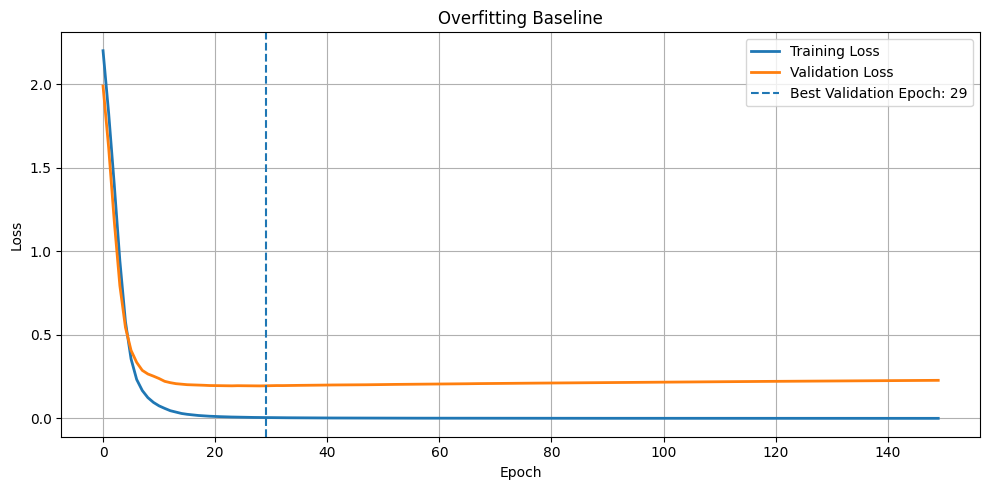

Best validation loss epoch: 29
Validation loss after minimum: 0.2279


In [6]:
# plot training and validation loss
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(baseline_history["train_loss"], label="Training Loss", lw=2)
ax.plot(baseline_history["val_loss"], label="Validation Loss", lw=2)

best_loss_epoch = np.argmin(baseline_history["val_loss"]) + 1

ax.axvline(best_loss_epoch, ls="--", label=f"Best Validation Epoch: {best_loss_epoch}")

ax.set(xlabel="Epoch", ylabel="Loss", title="Overfitting Baseline")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()


print("Best validation loss epoch:", best_loss_epoch)
print("Validation loss after minimum:", round(baseline_history["val_loss"][-1], 4))

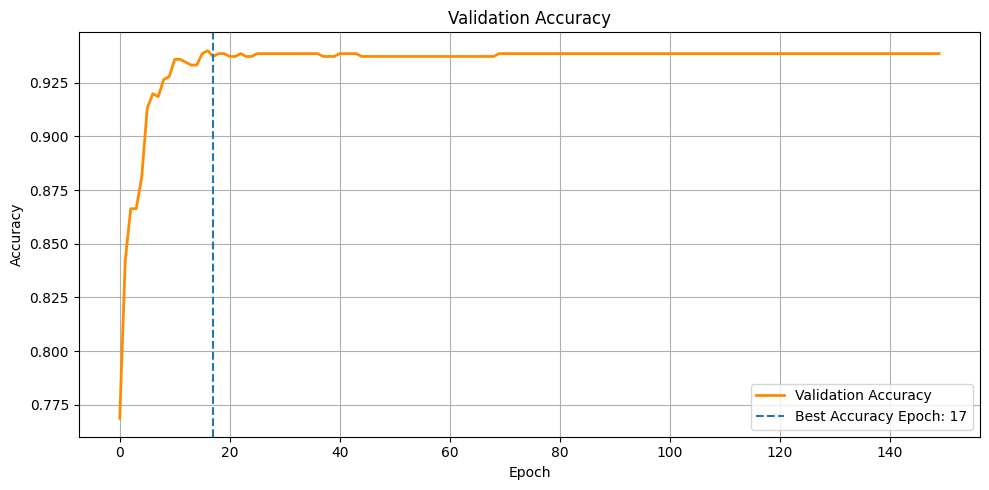

Best validation loss epoch: 29
Best validation accuracy epoch: 17


In [7]:
# Plot Validation Accuracy
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(baseline_history["val_acc"], label="Validation Accuracy", lw=2, color="darkorange")

best_accuracy_epoch = np.argmax(baseline_history["val_acc"]) + 1

ax.axvline(best_accuracy_epoch, ls="--", label=f"Best Accuracy Epoch: {best_accuracy_epoch}")

ax.set(xlabel="Epoch", ylabel="Accuracy", title="Validation Accuracy")
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

print("Best validation loss epoch:", best_loss_epoch)
print("Best validation accuracy epoch:", best_accuracy_epoch)

In [8]:
sizes = [300, 150, 75, 38, 19]

size_results = []

for size in sizes:
    Xa, Xrest, ya, yrest = train_test_split(X, y, train_size=size, random_state=0, stratify=y)
    Xv, _, yv, _ = train_test_split(Xrest, yrest, test_size=0.5, random_state=0, stratify=yrest)

    Xtr, ytr = to_tensor(Xa), to_tensor(ya, True)
    Xva, yva = to_tensor(Xv), to_tensor(yv, True)

    h, _ = train(make_model(), epochs=150, lr=0.001)
    train_val_gap = (h["val_loss"][-1] - h["train_loss"][-1])

    size_results.append({
        "Training Size": size,
        "Final Training Loss": h["train_loss"][-1],
        "Final Validation Loss": h["val_loss"][-1],
        "Loss Gap": train_val_gap,
        "Validation Accuracy": h["final_val_acc"]
    })


for result in size_results:
    print(result)


# Restore original split
Xtr, ytr = to_tensor(X_train), to_tensor(y_train, True)
Xva, yva = to_tensor(X_val), to_tensor(y_val, True)

{'Training Size': 300, 'Final Training Loss': 0.00018985091611587753, 'Final Validation Loss': 0.22785060107707977, 'Loss Gap': 0.2276607501609639, 'Validation Accuracy': 0.9385026693344116}
{'Training Size': 150, 'Final Training Loss': 0.0003942877461668104, 'Final Validation Loss': 0.42580321431159973, 'Loss Gap': 0.42540892656543294, 'Validation Accuracy': 0.9076549410820007}
{'Training Size': 75, 'Final Training Loss': 0.0007151331713733574, 'Final Validation Loss': 0.5346792936325073, 'Loss Gap': 0.5339641604611339, 'Validation Accuracy': 0.8571428656578064}
{'Training Size': 38, 'Final Training Loss': 0.0003911733510904014, 'Final Validation Loss': 0.6725919842720032, 'Loss Gap': 0.6722008109209128, 'Validation Accuracy': 0.7929465174674988}
{'Training Size': 19, 'Final Training Loss': 0.00031034069252200425, 'Final Validation Loss': 0.994642972946167, 'Loss Gap': 0.994332632253645, 'Validation Accuracy': 0.6749156713485718}


**Observation :-**
- Reducing the training dataset makes memorization easier.
- We compare training and validation loss at different dataset sizes.
- The dataset size at which the overfitting pattern disappears is identified from the experimental results.
- The minimum validation loss epoch and maximum validation accuracy epoch are also compared.
- These two epochs do not necessarily match because loss and accuracy measure different things.

# **Part B — The learning rate**
## **TASK 02 — Sweep it properly**

* Test different learning rates to understand their effect on neural network training.
* We will classify each learning rate into:
*    - Too Small
     - Good
     - Diverged

* We will record training loss, validation loss and accuracy.

In [9]:
import pandas as pd
import numpy as np

learning_rates = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]

lr_results = {}

for lr in learning_rates:
    print("Training learning rate:", lr)

    h, _ = train(make_model(), epochs=60, lr=lr)
    lr_results[lr] = h


rows = []

for lr, h in lr_results.items():

    initial_loss = h["train_loss"][0]
    final_loss = h["train_loss"][-1]
    max_loss = max(h["train_loss"])
    best_val_loss = min(h["val_loss"])
    val_accuracy = h["final_val_acc"]

    if (
        not np.isfinite(final_loss)
        or not np.isfinite(max_loss)
        or not np.isfinite(best_val_loss)
    ):
        category = "Diverged"

    elif lr >= 0.1:
        category = "Too Large"

    elif initial_loss - final_loss < 0.25 or final_loss > 1.0:
        category = "Too Small"

    else:
        category = "Good"

    rows.append({
        "Learning Rate": lr,
        "Final Training Loss": final_loss,
        "Best Validation Loss": best_val_loss,
        "Validation Accuracy": val_accuracy,
        "Category": category
    })


lr_table = pd.DataFrame(rows)

display(lr_table)

Training learning rate: 1e-05
Training learning rate: 0.0001
Training learning rate: 0.001
Training learning rate: 0.01
Training learning rate: 0.1
Training learning rate: 1.0


,Learning Rate,Final Training Loss,Best Validation Loss,Validation Accuracy,Category
0,0.00001,2.095410,2.113199,0.683155,Too Small
1,0.00010,0.224499,0.366542,0.919786,Good
2,0.00100,0.001131,0.194506,0.938503,Good
3,0.01000,0.000021,0.337126,0.927808,Good
4,0.10000,1.145282,1.141389,0.838235,Too Large
5,1.00000,1.762428,15.949230,0.216578,Too Large


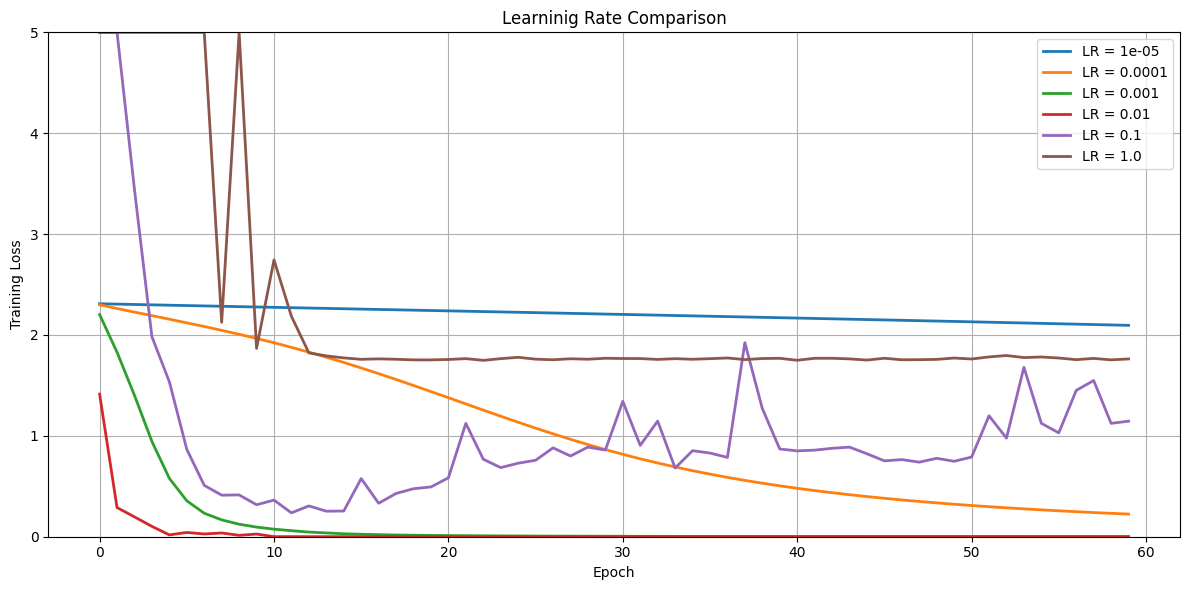

In [10]:
# Plot all learning rate curves
fi, ax = plt.subplots(figsize=(12, 6))
for lr, h in lr_results.items():
    ax.plot(np.clip(h["train_loss"], 0, 5), label=f"LR = {lr}", lw=2)


ax.set(xlabel="Epoch", ylabel="Training Loss", title="Learninig Rate Comparison")
ax.set_ylim(0, 5)
ax.legend()
ax.grid(0.7)

plt.tight_layout()
plt.show()

In [11]:
# Compare best and worst accuracy
best_lr = max(lr_results, key=lambda lr: lr_results[lr]["final_val_acc"])
worst_lr = min(lr_results, key=lambda lr: lr_results[lr]["final_val_acc"])

best_accuracy = lr_results[best_lr]["final_val_acc"]
worst_accuracy = lr_results[worst_lr]["final_val_acc"]

accuracy_gap = best_accuracy - worst_accuracy

good_rates = [lr for lr in learning_rates
             if lr_results[lr]["final_val_acc"] > 0
             and np.isfinite(lr_results[lr]["train_loss"][-1])
             and max(lr_results[lr]["train_loss"]) <= 5
             and lr_results[lr]["train_loss"][-1] <= 1.0]

print("Best Learning Rate:", best_lr)
print("Worst Learning Rate:", worst_lr)

print("\nBest Accuracy:", round(best_accuracy, 3))
print("Worst Accuracy:", round(worst_accuracy, 3))

print("\nAccuracy Gap:", round(accuracy_gap, 3))

if good_rates:
    print("Usable LR range:", min(good_rates), "to", max(good_rates))
    print("Usable LR Ratio:", max(good_rates) / min(good_rates))

Best Learning Rate: 0.001
Worst Learning Rate: 1.0

Best Accuracy: 0.939
Worst Accuracy: 0.217

Accuracy Gap: 0.722
Usable LR range: 0.0001 to 0.01
Usable LR Ratio: 100.0


**Observation :-**
- A very small learning rate produces slow learning.
- A suitable learning rate decreases training loss efficiently.
- An excessively large learning rate can cause unstable training or divergence.
- The usable range is identified using the numerical results rather than visual inspection alone.

## **TASK 03 — Build an LR finder**

**Objectives :-**
- Build a learning rate finder from scratch.
- The learning rate starts very small and increases after every training step.
- We record the loss against the learning rate.
- The steepest descending region is used to estimate a useful learning rate.

In [12]:
def lr_finder(lr_min=1e-6, lr_max=1.0, n_steps=120, seed=0, hidden=256, depth=2):
    torch.manual_seed(seed)
    model = make_model(hidden=hidden, depth=depth, seed=seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr_min)
    loss_fn = nn.CrossEntropyLoss()
    batch_size = min(64, len(Xtr))

    indices = torch.randperm(len(Xtr), device=device)[:batch_size]
    x_batch = Xtr[indices]
    y_batch = ytr[indices]
    multiplier = (lr_max / lr_min) ** (1 / n_steps)

    rates = []
    losses = []


    smoothed_loss = None
    beta = 0.9

    for step in range(n_steps):
        lr = lr_min * (multiplier ** step)

        for group in optimizer.param_groups:
            group["lr"] = lr

        model.train()
        optimizer.zero_grad()
        prediction = model(x_batch)
        loss = loss_fn(prediction, y_batch)

        if not torch.isfinite(loss):
            break

        loss.backward()
        optimizer.step()
        value = loss.item()

        if smoothed_loss is None:
            smoothed_loss = value
        else:
            smoothed_loss = (beta * smoothed_loss + (1 - beta) * value)

        rates.append(lr)
        losses.append(smoothed_loss)

        if value > 10:
            break

    rates = np.array(rates)
    losses = np.array(losses)

    # smooth the curve 
    smooth = np.convolve(losses, np.ones(5)/5, mode="valid")
    # calculate slope against log learning rate
    log_rates = np.log10(rates)


    slope = np.gradient(smooth, log_rates[:len(smooth)])
    best_index = np.argmin(slope)
    suggested_lr = rates[best_index + 2]

    return rates, losses, suggested_lr


rates, losses, suggested_lr = lr_finder()

print("Suggested Learning Rate:", suggested_lr)
print("Training Steps:", len(rates))

Suggested Learning Rate: 0.0019952623149688685
Training Steps: 120


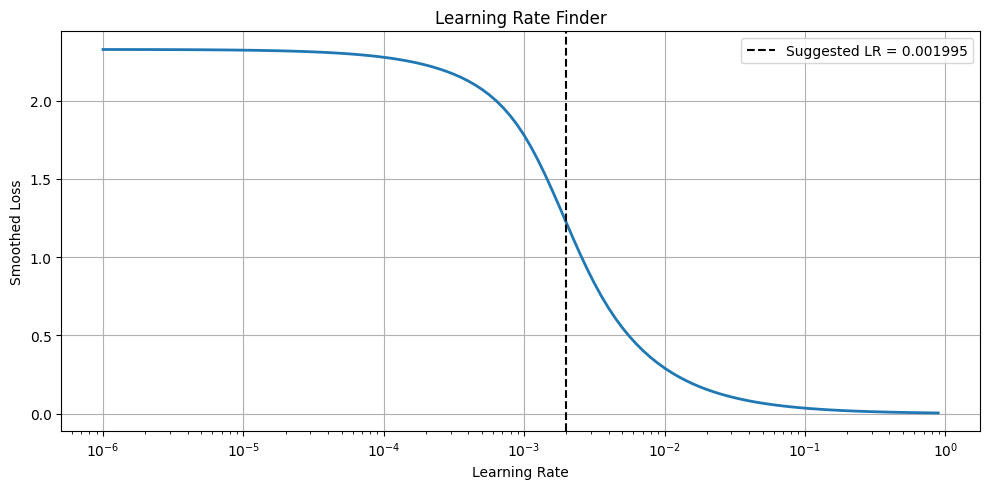

In [13]:
# Plot LR Finder 
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(rates, losses, lw=2)
ax.axvline(suggested_lr, ls="--", label=f"Suggested LR = {suggested_lr:.6f}", color="black")

ax.set(xscale="log", xlabel="Learning Rate", ylabel="Smoothed Loss", title="Learning Rate Finder")
ax.legend()
ax.grid(0.3)

plt.tight_layout()
plt.show()

In [14]:
# Compare finder with sweep
print("LR Finder suggestion:", suggested_lr)
print("Sweep best learning rate:", best_lr)

print("\nDifference Ratio:", max(suggested_lr, best_lr) / min(suggested_lr, best_lr))

LR Finder suggestion: 0.0019952623149688685
Sweep best learning rate: 0.001

Difference Ratio: 1.9952623149688684


In [15]:
# Test three random seeds
seed_results = []
for seed in [0, 42, 100]:
    rates, losses, suggested = lr_finder(seed=seed)
    seed_results.append({
        "Seed": seed,
        "Suggested LR": suggested,
        "Steps": len(rates)
    })


seed_table = pd.DataFrame(seed_results)

display(seed_table)

suggestions = [result["Suggested LR"] for result in seed_results]


print("Suggestion range:", min(suggestions), "to", max(suggestions))

,Seed,Suggested LR,Steps
0,0,0.001995,120
1,42,0.001995,120
2,100,0.002239,120


Suggestion range: 0.0019952623149688685 to 0.002238721138568327


In [16]:
# test different model sizes
model_sizes = [
    (64, 1),
    (256, 2),
    (512, 3)
]

model_lr_results = []

for hidden, depth in model_sizes:
    rates, losses, suggested = lr_finder(hidden=hidden, depth=depth, seed=0)
    model_lr_results.append({
        "Hidden Neurons": hidden,
        "Depth": depth,
        "Suggested LR": suggested
    })


display(pd.DataFrame(model_lr_results))

,Hidden Neurons,Depth,Suggested LR
0,64,1,0.007943
1,256,2,0.001995
2,512,3,0.000794


**Observation :-**
- The LR finder provides an estimate of a useful learning rate without requiring multiple complete training runs.
- The steepest descending point is preffered over the minimum loss because the minimum may occur after the learning rate has become too large.
- The finder is copared against the sweep result.
- Different random seed and model sizes are tested to measure the stability of the suggestion.

# **Part C — Measure each tool alone**
## **TASK 04 — Schedulers**

**Objectives :-**
- Compare different learning rate schedulers against a model without a scheduler.
- We will test:
  1. No Scheduler
  2. StepLR
  3. CosineAnnealingLR
  4. ReduceLROnPlateau
- We will compare learning rate changes and validation loss.

In [17]:
from torch.optim.lr_scheduler import (StepLR, CosineAnnealingLR, ReduceLROnPlateau)

schedulers = {
    "No Scheduler": None,
    "StepLR": lambda optimizer: StepLR(optimizer, step_size=20, gamma=0.3),
    "CosineAnnealingLR": lambda optimizer: CosineAnnealingLR(optimizer, T_max=150),
    "ReduceLROnPlateau": lambda optimizer: ReduceLROnPlateau(optimizer, factor=0.3, patience=5)
}

scheduler_results = {}

for name, scheduler in schedulers.items():
    print("Testing:", name)

    h, _ = train(make_model(), epochs=150, lr=0.001, scheduler=scheduler)

    scheduler_results[name] = h


scheduler_rows = []

for name, h in scheduler_results.items():
    scheduler_rows.append({
        "Scheduler": name,
        "Best Validation Loss": min(h["val_loss"]),
        "Validation Accuracy": h["final_val_acc"],
        "Final Learning Rate": h["lr"][-1]
    })


display(pd.DataFrame(scheduler_rows))

Testing: No Scheduler
Testing: StepLR
Testing: CosineAnnealingLR
Testing: ReduceLROnPlateau


,Scheduler,Best Validation Loss,Validation Accuracy,Final Learning Rate
0,No Scheduler,0.194506,0.938503,1.000000e-03
1,StepLR,0.195111,0.937166,2.187000e-07
2,CosineAnnealingLR,0.194429,0.938503,1.096583e-07
3,ReduceLROnPlateau,0.194506,0.938503,5.904900e-09


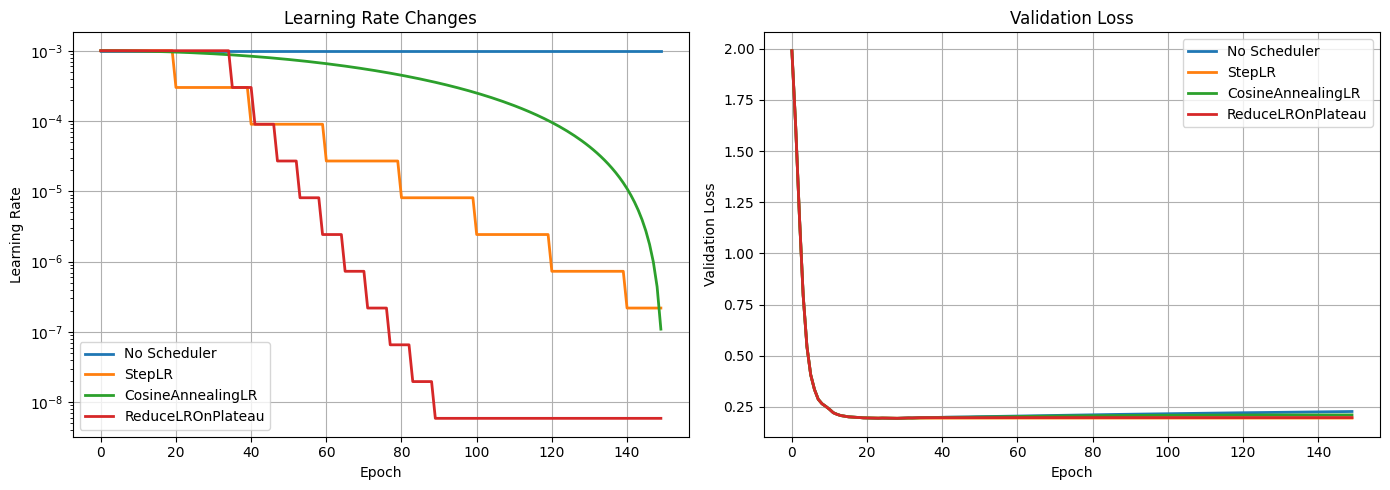

In [18]:
# Plot learning rate and Validation loss
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, h in scheduler_results.items():
    ax[0].plot(h["lr"], label=name, lw=2)
    ax[1].plot(h["val_loss"], label=name, lw=2)


ax[0].set(yscale="log", xlabel="Epoch", ylabel="Learning Rate", title="Learning Rate Changes")
ax[1].set(xlabel="Epoch", ylabel="Validation Loss", title="Validation Loss")

for ax in ax:
    ax.legend()
    ax.grid(0.3)


plt.tight_layout()
plt.show()

In [19]:
high_lr_results = {}

for name, scheduler in {"Fixed LR": None, 
                       "Cosine Scheduler": lambda optimizer: CosineAnnealingLR(optimizer, T_max = 250)}.items():
    h, _ = train(make_model(), epochs=250, lr=0.03, scheduler=scheduler)
    high_lr_results[name] = h


for name, h in high_lr_results.items():
    print("\n",name)


    print("Best Validation Loss:", round(min(h["val_loss"]), 4))
    print("Validation Accuracy:", round(h["final_val_acc"], 4))


 Fixed LR
Best Validation Loss: 0.5535
Validation Accuracy: 0.8877

 Cosine Scheduler
Best Validation Loss: 0.5535
Validation Accuracy: 0.8877


**Observation :-**
- StepLR changes the learning rate after fixed intervals.
- CosineAnnealing gradually reduces the learning rate.
- ReduceLROnPlateau reacts to Validation loss.
- Schedulers are useful when the model needs large updates early in training and smaller updates later.
- However, a scheduler is not guaranteed to improve every experiment.

## **TASK 05 — Dropout**

**Objectives :-**
- Measure the effect of dropout on overfitting.
- Dropout randomly disables a percentage of neurons during training.
- We will test multiple dropout values and compare:
  1. Training Loss
  2. Validation Loss
  3. Validation Accuracy
  4. Training - validation loss gap

In [20]:
dropout_values = [0.0, 0.2, 0.5, 0.8, 0.95]

dropout_results = {}
dropout_rows = []

for p in dropout_values:
    h, model = train(make_model(dropout=p), epochs=150, lr=0.001)
    dropout_results[p] = h
    final_train_loss = h["train_loss"][-1]
    best_val_loss = min(h["val_loss"])
    gap = best_val_loss - final_train_loss
    dropout_rows.append({
        "Dropout": p,
        "Final Training Loss": final_train_loss,
        "Best Validation Loss": best_val_loss,
        "Validation Accuracy": h["final_val_acc"],
        "Loss Gap": gap
    })



dropout_table = pd.DataFrame(dropout_rows)
display(dropout_table)

,Dropout,Final Training Loss,Best Validation Loss,Validation Accuracy,Loss Gap
0,0.00,0.000190,0.194506,0.938503,0.194317
1,0.20,0.000375,0.191732,0.942513,0.191357
2,0.50,0.013276,0.187644,0.945187,0.174368
3,0.80,0.107284,0.203113,0.937166,0.095829
4,0.95,1.895378,1.575822,0.836898,-0.319556


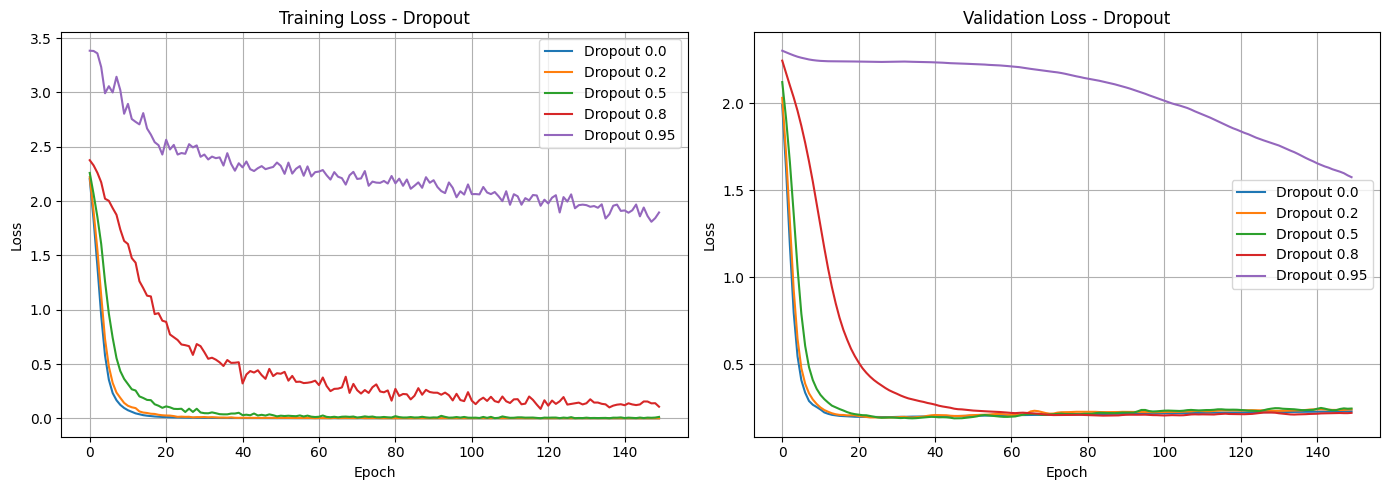

In [21]:
# Plot all dropout curves
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for p, h in dropout_results.items():
    ax[0].plot(h["train_loss"], label=f"Dropout {p}")
    ax[1].plot(h["val_loss"], label=f"Dropout {p}")


ax[0].set(xlabel="Epoch", ylabel="Loss", title="Training Loss - Dropout")
ax[1].set(xlabel="Epoch", ylabel="Loss", title="Validation Loss - Dropout")

for ax in ax:
    ax.legend()
    ax.grid(0.3)


plt.tight_layout()
plt.show()

In [22]:
# Find the dropout breaking point
for p, h in dropout_results.items():
    print(f"Dropout {p}: ",
         f"Train Loss = {h['train_loss'][-1]:.4f}",
         f"Val Loss = {min(h['val_loss']):.4f}",
         f"Accuracy = {h['final_val_acc']:.4f}")


best_dropout = max(dropout_results, key=lambda p: dropout_results[p]["final_val_acc"])

print("\nBest Dropout:", best_dropout)

Dropout 0.0:  Train Loss = 0.0002 Val Loss = 0.1945 Accuracy = 0.9385
Dropout 0.2:  Train Loss = 0.0004 Val Loss = 0.1917 Accuracy = 0.9425
Dropout 0.5:  Train Loss = 0.0133 Val Loss = 0.1876 Accuracy = 0.9452
Dropout 0.8:  Train Loss = 0.1073 Val Loss = 0.2031 Accuracy = 0.9372
Dropout 0.95:  Train Loss = 1.8954 Val Loss = 1.5758 Accuracy = 0.8369

Best Dropout: 0.5


**Train Mode vs Evaluation Mode :-**
* Dropout behaves differently during training and evaluation.
* In training mode, randomly selected neurons are disabled.
* In evaluation mode, dropout is disabled.
* We will send the same input through the model multiple times and compare the predictions.

In [23]:
dropout_model = make_model(dropout=0.5)
sample = Xva[:1]

# Training Mode
dropout_model.train()

with torch.no_grad():
    train_output_1 = dropout_model(sample)
    train_output_2 = dropout_model(sample)


# Evaluation mode
dropout_model.eval()

with torch.no_grad():
    eval_output_1 = dropout_model(sample)
    eval_output_2 = dropout_model(sample)


print("Train mode difference:", torch.max(torch.abs(train_output_1 - train_output_2)).item())

print("Evaluation mode difference:", torch.max(torch.abs(eval_output_1 - eval_output_2)).item())

Train mode difference: 0.8162006735801697
Evaluation mode difference: 0.0


**Observation :-**
- Dropout increases training loss because some neurons are randomly disabled during training.
- A suitable dropout value may reduce the difference between training and validation loss.
- However, excessive dropout causes underfitting.
- During training, repeated predictions can differ because dropout is active.
- During evaluation, repeated predictions should be identical because dropout is disabled.

## **TASK 06 — Weight decay**

**Objectives :-**
- Measure the effect of weight decay on a neural network.
- Weight decay penalizes unnecessarily large weights.
- We will compare different weight decay values and observe their effect on training loss, validation loss and accuracy.
- We will also compare Adam with AdamW.

In [24]:
weight_decay_values = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]

weight_decay_results = {}

weight_decay_rows = []


for wd in weight_decay_values:
    h, model = train(make_model(), epochs=150, lr=0.001, weight_decay=wd)
    weight_decay_results[wd] = {
        "history": h,
        "model": model
    }
    weight_decay_rows.append({
        "Weight Decay": wd,
        "Final Training Loss": h["train_loss"][-1],
        "Best Validation Loss": min(h["val_loss"]),
        "Validation Accuracy": h["final_val_acc"],
        "Loss Gap": min(h["val_loss"]) - h["train_loss"][-1]
    })


weight_decay_table = pd.DataFrame(weight_decay_rows)
display(weight_decay_table)

,Weight Decay,Final Training Loss,Best Validation Loss,Validation Accuracy,Loss Gap
0,0.0000,0.000190,0.194506,0.938503,0.194317
1,0.0001,0.000463,0.193203,0.938503,0.192740
2,0.0010,0.003962,0.176501,0.943850,0.172538
3,0.0100,0.037355,0.198901,0.943850,0.161546
4,0.1000,0.543388,0.648134,0.890374,0.104746


In [25]:
# Find best and worst settings
best_wd = max(weight_decay_results, key=lambda wd: weight_decay_results[wd]["history"]["final_val_acc"])
worst_wd = min(weight_decay_results, key=lambda wd: weight_decay_results[wd]["history"]["final_val_acc"])

print("Best Weight Decay:", best_wd)
print("Worst Weight Decay:", worst_wd)

Best Weight Decay: 0.001
Worst Weight Decay: 0.1


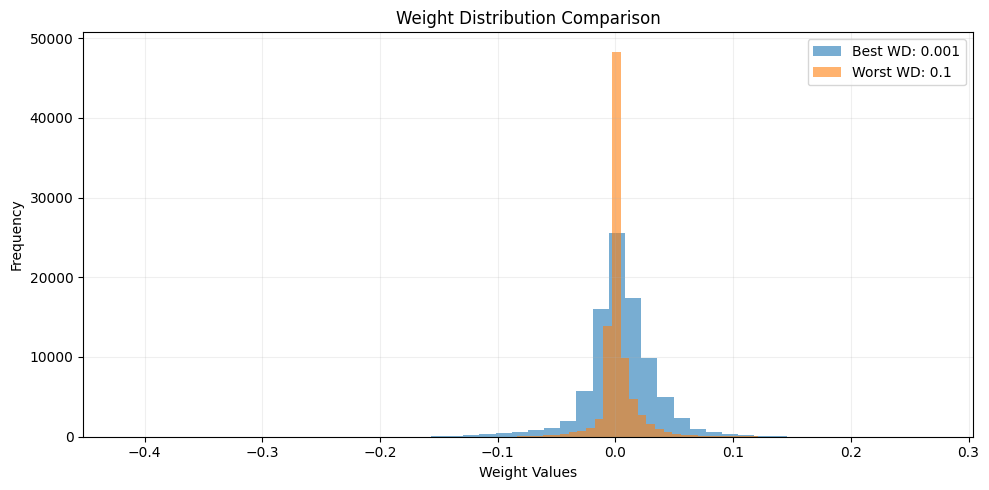

In [26]:
# Plot weight distributions
def get_weights(model):
    weights = []
    
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            weights.extend(layer.weight.detach().cpu().numpy().flatten())

    return np.array(weights)


best_weights = get_weights(weight_decay_results[best_wd]["model"])
worst_weights = get_weights(weight_decay_results[worst_wd]["model"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(best_weights, bins=50, alpha=0.6, label=f"Best WD: {best_wd}")
ax.hist(worst_weights, bins=50, alpha=0.6, label=f"Worst WD: {worst_wd}")

ax.set(xlabel="Weight Values", ylabel="Frequency", title="Weight Distribution Comparison")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [27]:
# Compare Adam and AdamW

adam_results = {}
for optimizer_name in ["adam", "adamw"]:
    h, model = train(make_model(), epochs=150, lr=0.001, weight_decay=float(best_wd), optimizer_name=optimizer_name)
    adam_results[optimizer_name] = h


    print("\nOptimizer:", optimizer_name)
    print("Validation Accuracy:", round(h["final_val_acc"], 4))
    print("Best Validation Loss:", round(min(h["val_loss"]), 4))


print("\nAdam vs AdamW Accuracy Difference:",
         abs(adam_results["adam"]["final_val_acc"] - adam_results["adamw"]["final_val_acc"]))


Optimizer: adam
Validation Accuracy: 0.9439
Best Validation Loss: 0.1765

Optimizer: adamw
Validation Accuracy: 0.9385
Best Validation Loss: 0.1945

Adam vs AdamW Accuracy Difference: 0.005347609519958496


**Observations :-**
- Weight decay discourages unnecessarily large weights.
- A suitable value can improve generalization.
- Too much weight decay can prevent the model from learning the training patterns properly.
- Adam and AdamW both support weight decay, but they handle it differently.
- AdamW applies decoupled weight decay, while the traditional Adam implementation incorporates weight decay through the gradient update.

## **TASK 07 — Batch normalisation**

**Objectives :-**
- Compare four neural network configurations:
  1. Plain Neural Network
  2. Batch Normalization
  3. Dropout
  4. Batch Normalization + Dropout
- We will compare validation accuracy, validation loss and the best epoch.
- We will also measure sensitivity to different learning rates.

In [28]:
bn_configs = {
    "Plain": {},
    "BatchNorm": {"batchnorm": True},
    "Dropout": {"dropout": 0.3},
    "BatchNorm + Dropout": {"batchnorm": True, 
                           "dropout": 0.3},
}

bn_results = {}
bn_rows = []

for name, model_args in bn_configs.items():
    h, model = train(make_model(**model_args), epochs=150, lr=0.001)
    bn_results[name] = {
        "history": h,
        "model": model
    }
    bn_rows.append({
        "Configuration": name,
        "Validation Accuracy": h["final_val_acc"],
        "Best Validation Loss": min(h["val_loss"]),
        "Best Epoch": np.argmin(h["val_loss"]) + 1
    })


bn_table = pd.DataFrame(bn_rows)

display(bn_table)

,Configuration,Validation Accuracy,Best Validation Loss,Best Epoch
0,Plain,0.938503,0.194506,29
1,BatchNorm,0.950535,0.174618,87
2,Dropout,0.938503,0.188071,26
3,BatchNorm + Dropout,0.945187,0.168212,49


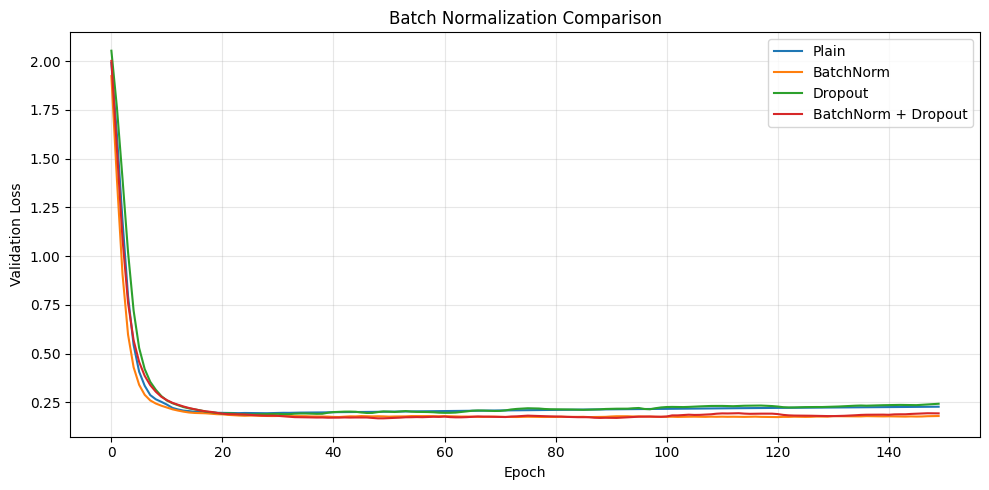

In [29]:
# Plot validation loss
fig, ax = plt.subplots(figsize=(10, 5))

for name, result in bn_results.items():
    ax.plot(result["history"]["val_loss"], label=name)


ax.set(xlabel="Epoch", ylabel="Validation Loss", title="Batch Normalization Comparison")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# Test learning rate sensitivity
bn_lr_values = [1e-4, 1e-3, 1e-2, 1e-1]
sensitivity_results = {}

for use_bn in [False, True]:
    name = "BatchNorm" if use_bn else "Plain"
    accuracies = []
    
    for lr in bn_lr_values:
        h, _ = train(make_model(batchnorm=use_bn), epochs=80, lr=lr)
        accuracies.append(h["final_val_acc"])

    sensitivity_results[name] = accuracies


sensitivity_table = pd.DataFrame(sensitivity_results, index=bn_lr_values)
display(sensitivity_table)


for name, values in sensitivity_results.items():
    print(name, "Accuracy Variation:", max(values) - min(values))

,Plain,BatchNorm
0.0001,0.923797,0.934492
0.0010,0.938503,0.947861
0.0100,0.927808,0.955882
0.1000,0.838235,0.933155


Plain Accuracy Variation: 0.10026735067367554
BatchNorm Accuracy Variation: 0.022727251052856445


In [31]:
# Verify Batch Normalization train/eval difference
bn_model = make_model(batchnorm=True)
sample = Xva[:32]

# Training Mode
bn_model.train()

with torch.no_grad():
    train_output = bn_model(sample)


# Evaluation Mode
bn_model.eval()

with torch.no_grad():
    eval_output = bn_model(sample)


difference = torch.mean(torch.abs(train_output - eval_output)).item()


print("Mean output difference:", difference)

Mean output difference: 0.27084681391716003


**Observation :-**
- Batch Normalization normalizes layer activations.
- It can improve training stability and reduce sensitivity to learning rate.
- Dropout randomly disables activations.
- Combining both techniques does not guarantee better results than using either one alone.
- Batch Normalization uses batch statistics during training and running statistics during evaluation.
- Therefore, model.train() and model.eval() are important.

## **TASK 08 — Early stopping**

**Objectives :-**
- Implement early stopping using validation performance.
- We will compare:
  1. Patience = 5
  2. Patience = 10
  3. Patience = 20
  4. No Early Stopping
- We will also compare stopping on validation loss and validation accuracy.

In [32]:
patience_values = [5, 10, 20, None]

early_results = {}
early_rows = []

for patience in patience_values:
    h, model = train(make_model(), epochs=150, lr=0.001, patience=patience, stop_metric="loss", restore_best=True)
    early_results[patience] = h
    early_rows.append({
        "Patience": patience,
        "Stopping Epoch": h["stopped_at"],
        "Best Epoch": h["best_epoch"],
        "Validation Accuracy": h["final_val_acc"],
        "Best Validation Loss": min(h["val_loss"]),
        "Epochs Saved": 150 - h["stopped_at"]
    })


early_table = pd.DataFrame(early_rows)

display(early_table)

,Patience,Stopping Epoch,Best Epoch,Validation Accuracy,Best Validation Loss,Epochs Saved
0,5.0,28,23,0.938503,0.194695,122
1,10.0,34,29,0.938503,0.194506,116
2,20.0,44,29,0.938503,0.194506,106
3,NaN,150,29,0.938503,0.194506,0


In [33]:
# Compare loss-based and accuracy-based stopping
stopping_comparison =  {}


for metric in ["loss", "acc"]:
    h, model = train(make_model(), epochs=150, lr=0.001, patience=10, stop_metric=metric, restore_best=True)
    stopping_comparison[metric] = h

    print("\nStopping Metric:", metric)
    print("Stopping Epoch:", h["stopped_at"])
    print("Best Epoch:", h["best_epoch"])
    print("Validation Accuracy:", h["final_val_acc"])
    print("Best Validation Loss:", min(h["val_loss"]))


Stopping Metric: loss
Stopping Epoch: 34
Best Epoch: 29
Validation Accuracy: 0.9385026693344116
Best Validation Loss: 0.1945064812898636

Stopping Metric: acc
Stopping Epoch: 21
Best Epoch: 17
Validation Accuracy: 0.9371657967567444
Best Validation Loss: 0.1961255818605423


In [34]:
# Compare restoring and not restoring the best model
restore_results = {}

for restore in [False, True]:
    h, model = train(make_model(), epochs=150, lr=0.001, patience=10, stop_metric="loss", restore_best=restore)
    restore_results[restore] = h

    print("\nRestore Best Model:", restore)
    print("Stopping Epoch:", h["stopped_at"])
    print("Best Epoch:", h["best_epoch"])
    print("Final Validation Loss:", h["final_val_loss"])
    print("Final Validation Accuracy:", h["final_val_acc"])


Restore Best Model: False
Stopping Epoch: 34
Best Epoch: 29
Final Validation Loss: 0.1970422863960266
Final Validation Accuracy: 0.9385026693344116

Restore Best Model: True
Stopping Epoch: 34
Best Epoch: 29
Final Validation Loss: 0.1970422863960266
Final Validation Accuracy: 0.9385026693344116


In [35]:
# Construct a long plateau experiment
# Artificial validation-loss sequence to demonstrate patience

validation_sequence = [1.0, 0.8, 0.6, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.4]


def simulate_early_stopping(values, patience):
    best = float("inf")
    bad_epochs = 0


    for epoch, value in enumerate(values, start=1):
        if value < best - 1e-4:
            best = value
            bad_epoch = 0

        else:
            bad_epochs += 1

            if bad_epochs >= patience:
                return epoch

    return len(values)


for patience in [2, 5, 10]:
    stopping_epoch = simulate_early_stopping(validation_sequence, patience)
    print(f"Patience {patience}: Stops at epoch {stopping_epoch}")

Patience 2: Stops at epoch 6
Patience 5: Stops at epoch 9
Patience 10: Stops at epoch 11


**Observation :-**
- Early stopping prevents unnecessary training.
- It monitors validation performance and stops training when improvement does not continue.
- Loss-based stopping and accuracy-based stopping may select different epochs.
- Restoring the best model is important because the final model may not be the best model encountered during training.
- A small patience value may stop training during a temporary plateau.

# **Part D — Diagnose from the curve alone**
## **TASK 09 — Produce and classify six broken runs**

**Observation :-**
- Create six neural network training experiments.
- Each experiment will demonstrate a different training problem:
  1. Learning rate too high
  2. Learning rate too low
  3. Overfitting
  4. Underfitting
  5. Healthy training
  6. Unstable training
- We will plot their training and validation losses and identify the problem using the curves.

In [36]:
curves = {}

# A. Learning rate too high
curves["A"] = train(make_model(), epochs=80, lr=1.0)[0]

# B. Learning rate too low
curves["B"] = train(make_model(), epochs=80, lr=1e-5)[0]

# C. Overfitting 
curves["C"] = train(make_model(hidden=512, depth=3), epochs=80, lr=0.01)[0]

# D. Underfitting
curves["D"] = train(make_model(hidden=2, depth=1), epochs=80, lr=0.01)[0]

# E. Healthy Training
curves["E"] = train(make_model(dropout=0.3), epochs=80, lr=0.003,
                   scheduler=lambda o: CosineAnnealingLR(o, T_max=80))[0]

# F. Unstable Training
curves["F"] = train(make_model(), epochs=80, lr=0.01, batch_size=2)[0]

print("All six experiments completed")

All six experiments completed


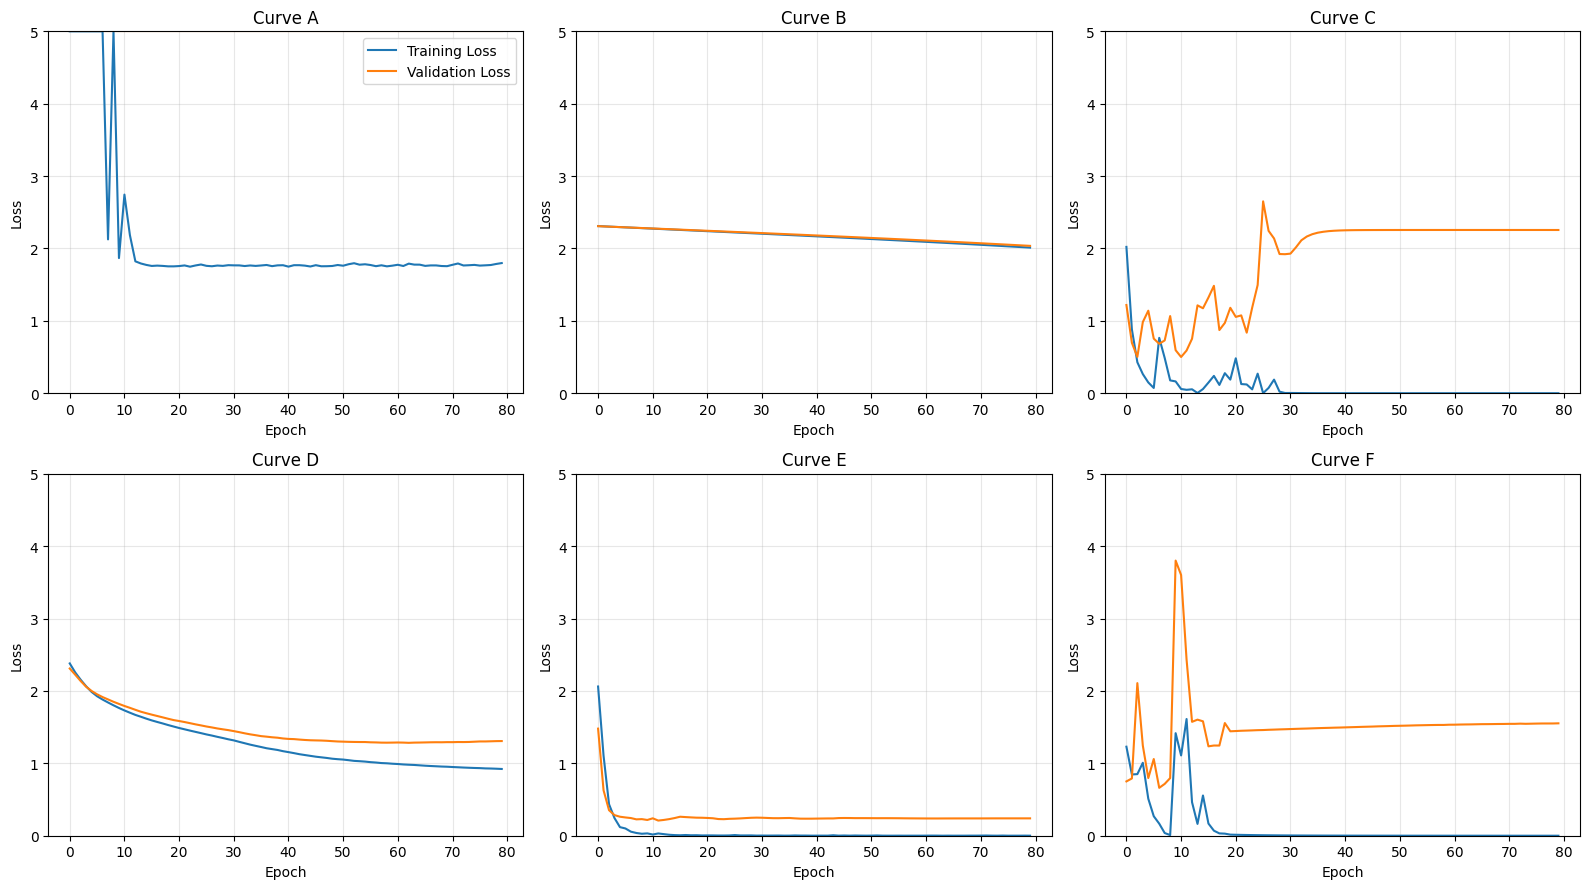

In [37]:
# Plot all six curves
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (name, h) in zip(axes.ravel(), curves.items()):
    ax.plot(np.clip(h["train_loss"], 0, 5), label="Training Loss")
    ax.plot(np.clip(h["val_loss"], 0, 5), label="Validation Loss")

    ax.set(xlabel="Epoch", ylabel="Loss", title=f"Curve {name}")
    ax.set_ylim(0, 5)
    ax.grid(alpha=0.3)


axes[0, 0].legend()

plt.tight_layout()
plt.show()

In [38]:
# Automatic diagnostic table
diagnoses = {
    "A": {
        "Problem": "Learning Rate Too High",
        "Meaning": "Loss jumps or diverges",
        "Solution": "Reduce learning rate"
    },

    "B": {
        "Problem": "Learning Rate Too Low",
        "Meaning": "Loss decreases very slowly",
        "Solution": "Increase learning rate"
    },

    "C": {
        "Problem": "Overfitting",
        "Meaning": "Training loss decreases but validation loss increases",
        "Solution": "Use regularization"
    },

    "D": {
        "Problem": "Underfitting",
        "Meaning": "Both losses remain high",
        "Solution": "Increase model capacity"
    },

    "E": {
        "Problem": "Healthy Training",
        "Meaning": "Both losses decrease and stabilize",
        "Solution": "Continue monitoring"
    },

    "F": {
        "Problem": "Unstable Training",
        "Meaning": "Loss fluctuates heavily",
        "Solution": "Increase batch size or reduce learning rate"
    }
}

diagnostic_rows = []

for name, h in curves.items():
    diagnostic_rows.append({
        "Curve": name,
        "Problem": diagnoses[name]["Problem"],
        "Final Validation Loss": h["val_loss"][-1],
        "Final Training Loss": h["train_loss"][-1],
        "Validation Accuracy": h["final_val_acc"],
        "Solution": diagnoses[name]["Solution"]
    })



diagnostic_table = pd.DataFrame(diagnostic_rows)
display(diagnostic_table)

,Curve,Problem,Final Validation Loss,Final Training Loss,Validation Accuracy,Solution
0,A,Learning Rate Too High,64.119118,1.798106,0.216578,Reduce learning rate
1,B,Learning Rate Too Low,2.035968,2.011896,0.766043,Increase learning rate
2,C,Overfitting,2.255224,0.000003,0.926471,Use regularization
3,D,Underfitting,1.307972,0.922315,0.534759,Increase model capacity
4,E,Healthy Training,0.239921,0.000527,0.945187,Continue monitoring
5,F,Unstable Training,1.552925,0.000059,0.911765,Increase batch size or reduce learning rate


**Experiment: Dropout on Underfitting**
- Regularization is useful for controlling overfitting.
- However, adding regularization to an already underfitting model may make its performance worse.
- We will compare a small model with and without dropout.

In [39]:
underfit_results = {}

for name, dropout in [
    ("Without Dropout", 0.0),
    ("With Dropout", 0.5)
]:
    h, model = train(make_model(hidden=2, depth=1, dropout=dropout), epochs=80, lr=0.01)
    underfit_results[name] = h

    print("\n", name)
    print("Training Loss:", round(h["train_loss"][-1], 4))
    print("Validation Loss:", round(h["val_loss"][-1], 4))
    print("Validation Accuracy:", round(h["final_val_acc"], 4))


 Without Dropout
Training Loss: 0.9223
Validation Loss: 1.308
Validation Accuracy: 0.5348

 With Dropout
Training Loss: 1.8791
Validation Loss: 1.8782
Validation Accuracy: 0.3917


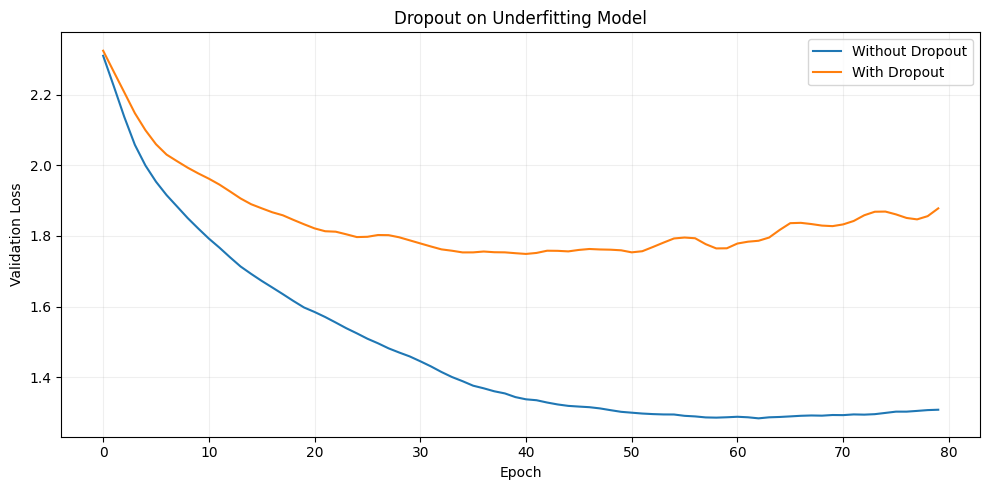

In [40]:
# Plot the comparison
fig, ax = plt.subplots(figsize=(10, 5))

for name, h in underfit_results.items():
    ax.plot(h["val_loss"], label=name)


ax.set(xlabel="Epoch", ylabel="Validation Loss", title="Dropout on Underfitting Model")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Observation :-**
- Training and validation curves help diagnose model behavior.
- Overfitting and underfitting are different problems.
- Overfitting has a large difference between training and validation performance.
- Underfitting has poor performance on both training and validation data.
- Adding dropout to an underfitting model can make the problem worse.
- Both training and validation curves should always be plotted.

# **Part E — Put it together honestly**
## **TASK 10 — All tools, against the noise**

**Objectives :-**
- Compare the baseline model with individual training techniques and a combined configuration.
- Every experiment will use the same seed and dataset split.
- We will identify:
  1. Best single tool
  2. Best overall configuration
  3. Improvement over baseline
  4. Variation caused by random data splits
- The purpose is to understand whether the improvement is actually meaningful or just random variation.

In [41]:
# Select the best usable learning rate
# Select only from learning rates classified as good.

best_lr = max(good_rates, key=lambda lr: lr_results[lr]["final_val_acc"])

print("Selected Learning Rate:", best_lr)
print("Selected Learning Rate Accuracy:", lr_results[best_lr]["final_val_acc"])

Selected Learning Rate: 0.001
Selected Learning Rate Accuracy: 0.9385026693344116


In [42]:
# Compare baseline and individual techniques
from torch.optim.lr_scheduler import CosineAnnealingLR

# Select the best weight decay using validation accuracy
best_wd = max(weight_decay_results, key=lambda wd: weight_decay_results[wd]["history"]["final_val_acc"])


print("Selected Weight Decay:", best_wd)

configs = {
    "Baseline": {
        "model": {},
        "train": {}
    },
     "Scheduler Only": {

        "model": {},

        "train": {
            "scheduler": lambda o: CosineAnnealingLR(
                o,
                T_max=150
            )
        }
    },

    "Dropout Only": {

        "model": {
            "dropout": 0.3
        },

        "train": {}
    },

    "Weight Decay Only": {

        "model": {},

        "train": {
            "weight_decay": float(best_wd)
        }
    },

    "BatchNorm Only": {

        "model": {
            "batchnorm": True
        },

        "train": {}
    },

    "Early Stopping Only": {

        "model": {},

        "train": {
            "patience": 10
        }
    },

    "Everything": {

        "model": {
            "dropout": 0.3,
            "batchnorm": True
        },

        "train": {
            "weight_decay": float(best_wd),
            "patience": 10,
            "scheduler": lambda o: CosineAnnealingLR(
                o,
                T_max=150
            )
        }
    }
}


final_results = {}

final_rows = []

for name, config in configs.items():

    print("Training:", name)

    train_args = {
        "epochs": 150,
        "lr": float(best_lr)
    }

    train_args.update(config["train"])

    h, model = train(
        make_model(**config["model"]),
        **train_args
    )

    final_results[name] = {
        "history": h,
        "model": model
    }

    final_rows.append({

        "Configuration": name,

        "Validation Accuracy": h["final_val_acc"],

        "Best Validation Loss": min(h["val_loss"]),

        "Training Epochs": h["stopped_at"]
    })


final_table = pd.DataFrame(final_rows)

display(final_table)


Selected Weight Decay: 0.001
Training: Baseline
Training: Scheduler Only
Training: Dropout Only
Training: Weight Decay Only
Training: BatchNorm Only
Training: Early Stopping Only
Training: Everything


,Configuration,Validation Accuracy,Best Validation Loss,Training Epochs
0,Baseline,0.938503,0.194506,150
1,Scheduler Only,0.938503,0.194429,150
2,Dropout Only,0.938503,0.188071,150
3,Weight Decay Only,0.943850,0.176501,150
4,BatchNorm Only,0.950535,0.174618,150
5,Early Stopping Only,0.938503,0.194506,34
6,Everything,0.945187,0.165155,55


In [44]:
# Find the best single tool and best overall configuration
baseline_accuracy = final_results["Baseline"]["history"]["final_val_acc"]

single_tool_names = ["Scheduler Only", "Dropout Only", "Weight Decay Only", "BatchNorm Only", "Early Stopping Only"]

best_single_tool = max(single_tool_names, key=lambda name: final_results[name]["history"]["final_val_acc"])
best_overall = max(final_results, key=lambda name: final_results[name]["history"]["final_val_acc"])

best_single_accuracy = (final_results[best_single_tool]["history"]["final_val_acc"])
overall_accuracy = (final_results[best_overall]["history"]["final_val_acc"])

baseline_improvement = overall_accuracy - baseline_accuracy
stack_improvement = overall_accuracy - best_single_accuracy

print("Baseline Accuracy:", baseline_accuracy)
print("Best Single Tool:", best_single_tool)
print("Best Single Accuracy:", best_single_accuracy)
print("Best Overall Configuration:", best_overall)
print("Overall Accuracy:", overall_accuracy)
print("Improvement over Baseline:", baseline_improvement)
print("Full Stack vs Best Single:", stack_improvement)

Baseline Accuracy: 0.9385026693344116
Best Single Tool: BatchNorm Only
Best Single Accuracy: 0.9505347609519958
Best Overall Configuration: BatchNorm Only
Overall Accuracy: 0.9505347609519958
Improvement over Baseline: 0.012032091617584229
Full Stack vs Best Single: 0.0


In [48]:
# Random split variation
split_accuracies = []

for seed in [0, 1, 2, 3, 4, 5]:
    Xa, Xremaining, ya, yremaining = train_test_split(X, y, train_size=300, random_state=seed, stratify=y)

    Xv, _, yv, _ = train_test_split(Xremaining, yremaining, test_size=0.5, random_state=seed, stratify=yremaining)

    # Update training and validation data
    Xtr, ytr = to_tensor(Xa), to_tensor(ya, True)
    Xva, yva = to_tensor(Xv), to_tensor(yv, True)

    h, _ = train(make_model(seed=0), epochs=150, lr=0.001)

    split_accuracies.append(h["final_val_acc"])



# Restore original split
Xtr, ytr = to_tensor(X_train), to_tensor(y_train, True)
Xva, yva = to_tensor(X_val), to_tensor(y_val, True)


print("Six Split Accuracies:")
print(split_accuracies)


split_spread = (max(split_accuracies) - min(split_accuracies))

print("Tuning Improvement:", baseline_improvement)
print(
    "Which is Larger:",
    "Split Variation" if split_spread > abs(baseline_improvement)
    else "Tuning Improvement"
)

Six Split Accuracies:
[0.9385026693344116, 0.9759358763694763, 0.9398396015167236, 0.9425134062767029, 0.9224599003791809, 0.9451872110366821]
Tuning Improvement: 0.012032091617584229
Which is Larger: Split Variation


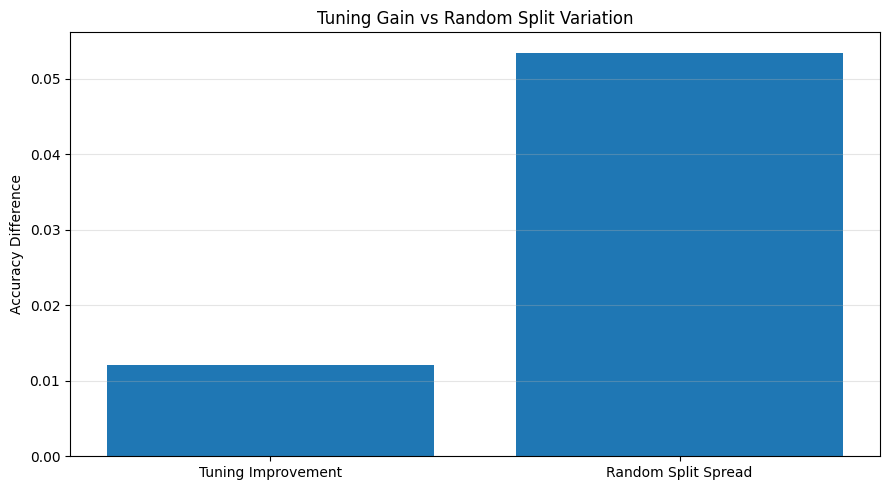

In [49]:
# Compare improvement and split variation
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    ["Tuning Improvement", "Random Split Spread"],
    [abs(baseline_improvement), split_spread]
)

ax.set(ylabel="Accuracy Difference", title="Tuning Gain vs Random Split Variation")
ax.grid(axis="y", alpha=0.32)

plt.tight_layout()
plt.show()

**Observation :-**
- The tuning improvement and random split spread must be compared together.
- If random split variation is larger than tuning improvement, we cannot confidently claim that the tuned configuration is genuinely better.
- This does not mean tuning is useless.
- It means that more experiments and more random splits may be needed to establish whether the improvement is reliable.
- Both numbers must be reported honestly.

In [50]:
if split_spread > abs(baseline_improvement):

    conclusion = """
    Random split variation is larger than the tuning improvement.

    Therefore, the current improvement is within the observed
    experimental noise. We cannot confidently claim that the
    tuned configuration is consistently better than the baseline.
    More repeated experiments are needed.
    """

else:

    conclusion = """
    The tuning improvement is larger than the observed random
    split variation.

    This provides stronger evidence that the selected
    configuration improves performance on this dataset.
    However, additional splits would make the conclusion
    more reliable.
    """


print(conclusion)


    Random split variation is larger than the tuning improvement.

    Therefore, the current improvement is within the observed
    experimental noise. We cannot confidently claim that the
    tuned configuration is consistently better than the baseline.
    More repeated experiments are needed.
    


# **Part F — The test set, once**
## **TASK 11 — Report a final number**

**Objectives :-**
- Select the final model using variation results only.
- After selecting the best configuration, evaluate it on the test dataset exactly once.
- We will report validation accuracy and test accuracy side by side.
- We will not make any further tuning decisions using the test results.

In [53]:
# Select configuration using validation accuracy only
final_config_name = best_overall
selected_config = configs[final_config_name]

print("Selected Configuration:", final_config_name)
print("Validation Accuracy:", final_results[final_config_name]["history"]["final_val_acc"])

Selected Configuration: BatchNorm Only
Validation Accuracy: 0.9505347609519958


In [56]:
# Train final model
final_train_args = {"epochs": 150,
                   "lr": float(best_lr)}
final_train_args.update(selected_config["train"])
final_model = make_model(**selected_config["model"])

final_history, final_model = train(final_model, **final_train_args)


print("Final model training completed.")
print("Validation Accuracy:", final_history["final_val_acc"])

Final model training completed.
Validation Accuracy: 0.9505347609519958


In [59]:
# Evaluate test dataset - Only once
# This is the only test set evaluation

final_model.eval()

test_loss_fn = nn.CrossEntropyLoss()

with torch.no_grad():
    test_predictions = final_model(Xte)
    test_loss = test_loss_fn(test_predictions, yte).item()
    test_accuracy = (test_predictions.argmax(1) == yte).float().mean().item()


validation_accuracy = final_history["final_val_acc"]


print("FINAL EVALUATION")
print("-" * 17)

print("\nValidation Accuracy:", round(validation_accuracy, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Loss:", round(test_loss, 4))
print("Difference:", round(test_accuracy - validation_accuracy, 4))

FINAL EVALUATION
-----------------

Validation Accuracy: 0.9505
Test Accuracy: 0.9546
Test Loss: 0.1399
Difference: 0.0041


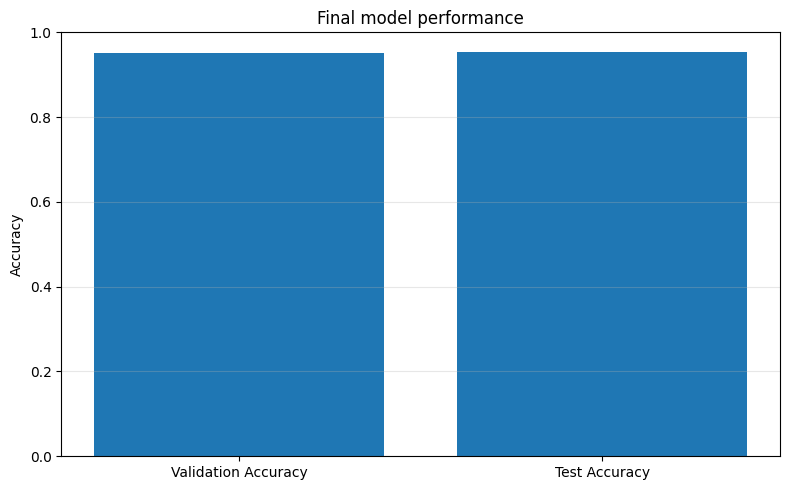

In [60]:
# Final comparison graph
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["Validation Accuracy", "Test Accuracy"],
    [validation_accuracy, test_accuracy]
)

ax.set(ylabel="Accuracy", title="Final model performance")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Observation :-**
- The final model was selected using validation performance.
- The test dataset was used only once for final evaluation.
- The validation and test scores may differ because they contain different examples.
- A lower test score does not mean we should tune the model again using the test dataset.
- The test set provides an independent estimate of generalization performance.

# **Part G — Push further**

**Objectives :-**
- Investigate label smoothing in neural network classification.
- Normally, the correct class has a target probability of 1 and all other classes have a probability of 0.
- label smoothing makes the target distribution less extreme.
- We will compare normal cross entropy against label smoothing using validation performance.

In [61]:
label_smoothing_results = {}

for smoothing in [0.0, 0.05, 0.1, 0.2]:
    h, model = train(make_model(), epochs=150, lr=float(best_lr), label_smoothing=smoothing)
    label_smoothing_results[smoothing] = h

    
    print("\nLabel Smoothing:", smoothing)
    print("Validation Accuracy:", round(h["final_val_acc"], 4))
    print("Best Validation Loss:", round(min(h["val_loss"]), 4))


Label Smoothing: 0.0
Validation Accuracy: 0.9385
Best Validation Loss: 0.1945

Label Smoothing: 0.05
Validation Accuracy: 0.9532
Best Validation Loss: 0.4342

Label Smoothing: 0.1
Validation Accuracy: 0.9559
Best Validation Loss: 0.6481

Label Smoothing: 0.2
Validation Accuracy: 0.9559
Best Validation Loss: 0.999


In [62]:
# Compare label smoothing
smoothing_rows = []

for smoothing, h in label_smoothing_results.items():
    smoothing_rows.append({
        "Label Smoothing": smoothing,
        "Validation Accuracy": h["final_val_acc"],
        "Best Validation Loss": min(h["val_loss"]),
        "Final Training Loss": h["train_loss"][-1]
    })



smoothing_table = pd.DataFrame(smoothing_rows)

display(smoothing_table)

,Label Smoothing,Validation Accuracy,Best Validation Loss,Final Training Loss
0,0.00,0.938503,0.194506,0.000190
1,0.05,0.953209,0.434202,0.283399
2,0.10,0.955882,0.648100,0.501000
3,0.20,0.955882,0.999020,0.867302


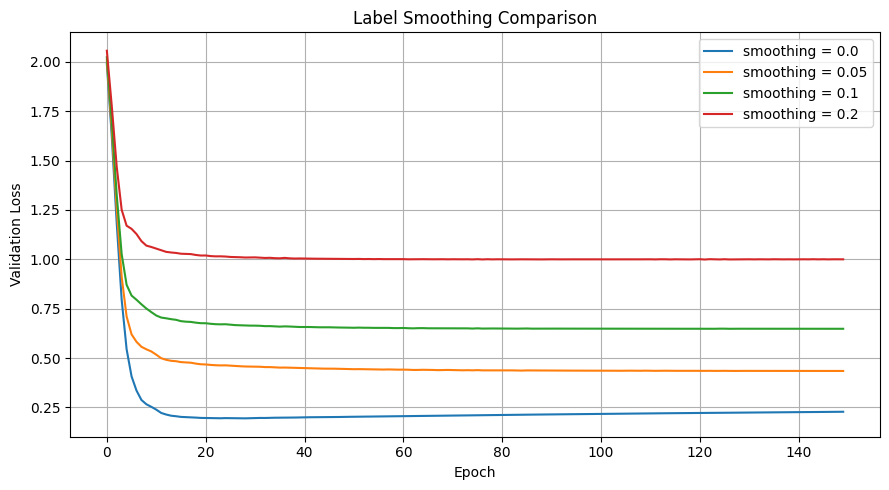

In [63]:
# Plot the results
fig, ax = plt.subplots(figsize=(9, 5))

for smoothing, h in label_smoothing_results.items():
    ax.plot(h["val_loss"], label=f"smoothing = {smoothing}")


ax.set(xlabel="Epoch", ylabel="Validation Loss", title="Label Smoothing Comparison")
ax.legend()
ax.grid(0.3)

plt.tight_layout()
plt.show()

**Observation :-**
- Label smoothing prevents the model from becoming excessively confident in its predictions.
- It changes the target distribution used by the cross entropy loss.
- A suitable smoothing value may improve generalization.
- However, excessive label smoothing can reduce the model's ability to learn the correct class confidently.
- The best value is selected using validation results.

# **Final Report**

**Day 49 – Training Dynamics and Regularization Report**
**1. Learning Rate Sweep :-**
- Different learning rates were tested.
- The usable learning rate range was identified by comparing training loss and validation accuracy.
- The LR finder was also compared against the best learning rate from the sweep.

**2. Individual Tool Results :-**  
The following techniques were evaluated independently:
- Learning Rate Scheduling
- Dropout
- Weight Decay
- Batch Normalization
- Early Stopping  

Each technique was compared against the baseline model.

**3. Best Configuration :-**
- The best configuration was selected using validation accuracy.
- Its improvement over the baseline was calculated.

**4. Random Split Variation :-**
- Six different train-validation splits were tested.
- The variation in accuracy was compared against the improvement obtained through tuning.

**5. Final Test Evaluation :-**
- The selected model was evaluated on the test dataset once.
- Its test performance was compared with validation performance.

**6. Open Question :-**
- How many independent random splits are required to establish that a small improvement is statistically reliable?

In [64]:
print("=" * 65)
print("DAY 49 – FINAL PROJECT REPORT")
print("=" * 65)

print("\n1. LEARNING RATE SWEEP")

print("Usable learning rates:", good_rates)

print("Selected learning rate:", best_lr)

print("LR Finder suggestion:", suggested_lr)


print("\n2. INDIVIDUAL TECHNIQUES")

print(
    "Best Scheduler:",
    max(
        scheduler_results,
        key=lambda k: scheduler_results[k]["final_val_acc"]
    )
)

print("Best Dropout:", best_dropout)

print("Best Weight Decay:", best_wd)

print(
    "Best Batch Normalization Configuration:",
    max(
        bn_results,
        key=lambda k: bn_results[k]["history"]["final_val_acc"]
    )
)

print(
    "Early Stopping Best Patience:",
    max(
        early_results,
        key=lambda p: early_results[p]["final_val_acc"]
    )
)


print("\n3. BEST CONFIGURATION")

print("Best Single Tool:", best_single_tool)

print("Best Overall:", best_overall)

print("Baseline Accuracy:", round(baseline_accuracy, 4))

print("Best Accuracy:", round(overall_accuracy, 4))

print(
    "Improvement:",
    round(baseline_improvement, 4)
)


print("\n4. RANDOM SPLIT VARIATION")

print("Split Accuracies:", split_accuracies)

print("Split Spread:", round(split_spread, 4))

print(
    "Larger Effect:",
    "Random Split Variation"
    if split_spread > abs(baseline_improvement)
    else "Tuning Improvement"
)


print("\n5. FINAL TEST EVALUATION")

print("Validation Accuracy:", round(validation_accuracy, 4))

print("Test Accuracy:", round(test_accuracy, 4))

print("Test Loss:", round(test_loss, 4))


print("\n6. OPEN QUESTION")

print(
    "How many independent random splits are required "
    "to detect a small performance improvement reliably?"
)

print("\n" + "=" * 65)
print("DAY 49 COMPLETED")
print("=" * 65)

DAY 49 – FINAL PROJECT REPORT

1. LEARNING RATE SWEEP
Usable learning rates: [0.0001, 0.001, 0.01]
Selected learning rate: 0.001
LR Finder suggestion: 0.0019952623149688685

2. INDIVIDUAL TECHNIQUES
Best Scheduler: No Scheduler
Best Dropout: 0.5
Best Weight Decay: 0.001
Best Batch Normalization Configuration: BatchNorm
Early Stopping Best Patience: 5

3. BEST CONFIGURATION
Best Single Tool: BatchNorm Only
Best Overall: BatchNorm Only
Baseline Accuracy: 0.9385
Best Accuracy: 0.9505
Improvement: 0.012

4. RANDOM SPLIT VARIATION
Split Accuracies: [0.9385026693344116, 0.9759358763694763, 0.9398396015167236, 0.9425134062767029, 0.9224599003791809, 0.9451872110366821]
Split Spread: 0.0535
Larger Effect: Random Split Variation

5. FINAL TEST EVALUATION
Validation Accuracy: 0.9505
Test Accuracy: 0.9546
Test Loss: 0.1399

6. OPEN QUESTION
How many independent random splits are required to detect a small performance improvement reliably?

DAY 49 COMPLETED
